# Control vs Diacerein — RNA-seq pipeline (v15)

Differential expression is fitted here **from the count matrix**, not read from a pre-computed
`DE_D_Vs_C.xlsx`. No realignment is needed: `counts.txt` holds the RSEM expected counts, which is
what DESeq2 takes as input.

**Inputs:** `counts.txt` (RSEM expected counts, 6 samples), `tpm.txt` (per-sample TPM).

**Cohort.** `PRIMARY_DROP = ['D4']` — D4 is excluded from the primary analysis as a treatment
non-responder. Both cohorts are computed every run and reported side by side in the sensitivity
table, so the effect of the exclusion stays visible.

How to state this in a manuscript: the response was seen in **2 of 3** treated animals, and the
primary analysis conditions on those two. "Non-responder" is a biological reading of the data, not
a quality-control criterion — D4 passes every QC metric in section 4 — so excluding it narrows the
claim to the responding animals and inflates the effect sizes relative to the full cohort. Set
`PRIMARY_DROP = []` to see the all-six result.

**Outputs:** DE table, GO enrichment spreadsheet, KEGG GSEA figure, volcano, PCA, QC panel.

**Panel sizing.** Panels C and D of Figure 1 share two thirds of an 18 cm figure, so each is built at `PANEL_W_CM` (5.8 cm) with fixed margins and saved without `bbox_inches='tight'` — the PDF comes out at exactly the requested size, so the panels drop into the layout without rescaling. Rescaling a figure in the layout program is what pushes text below the 8 pt floor.

**AHA figure compliance.** All figure text sits at or above the AHA 8-point floor (`AHA_MIN_FONT`), and on-figure headings are off by default (`SHOW_TITLES = False`), since AHA asks for heading information in the legend rather than on the figure. Set `SHOW_TITLES = True` while working if you want titles on screen; leave it False for the files you submit.

Runs `pydeseq2`, which implements the same negative-binomial model as R's DESeq2 and agrees
closely but not to the last digit. Refit the final model in R for anything going to press.

In [1]:
#@title 1 · Setup
!pip install pydeseq2 gprofiler-official -q

import pandas as pd, numpy as np, warnings
import matplotlib, matplotlib.pyplot as plt
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
warnings.filterwarnings('ignore')

# ── Config — edit here ──────────────────────────────────────────────────────
CTRL   = ['C2', 'C3', 'C4']
TREAT  = ['D2', 'D3', 'D4']
PRIMARY_DROP = ['D4']       # excluded from the PRIMARY analysis (non-responder); [] keeps all six

PADJ_CUT, LFC_CUT, TPM_MIN = 0.05, 1.0, 1.0
MIN_COUNT_SUM = 10          # gene-level prefilter across all samples
# Genes labelled on the volcano. Named explicitly so the figure points at the genes the
# manuscript argues from, rather than whichever happen to have the smallest adjusted P.
LABEL_GENES = ['Selp', 'Csf2rb', 'Ripk1', 'Card9', 'Il1b']
N_LABEL = 5                 # fallback: top-N by padj if LABEL_GENES is empty

COL_DOWN, COL_UP, COL_NS = '#4daa61', '#a070c0', '#c0c0c0'
COL_C,   COL_D           = '#e4785f', '#36b8b8'

# ── Panel geometry ─────────────────────────────────────────────────────────
# Figure 1 is 18 cm wide; panels C and D together occupy two thirds of it.
PAGE_W_CM    = 18.0
PANEL_W_CM   = (PAGE_W_CM * 2/3 - 0.4) / 2      # 5.8 cm each, 0.4 cm gutter
PANEL_H_CM   = 5.6
# Margins inside each panel, in cm: left, right, bottom, top
MARGIN = dict(l=1.35, r=0.15, b=1.05, t=0.15)
# Short names keep the KEGG legend inside 5.8 cm at 8 pt; full names and the
# ES / adjusted P values belong in the figure legend text.
KEGG_SHORT = {'tnf signaling pathway': 'TNF signaling',
              'nf-\u03bab signaling pathway': 'NF-\u03baB signaling',
              'cytokine-cytokine receptor interaction': 'Cytokine receptor'}
def short_name(s):
    """Match regardless of hyphen/en-dash and case; fall back to the full name."""
    k = s.lower().replace('\u2013', '-').replace('\u2014', '-')
    return KEGG_SHORT.get(k, s)
LEGEND_WITH_STATS = False   # True puts ES and adj.P on the panel itself

# AHA journals: figure text 8-10 pt, headings in the legend not on the figure.
AHA_MIN_FONT = 8
SHOW_TITLES  = False

CM = 1/2.54
STYLE = {'font.family':'sans-serif',
         'font.sans-serif':['Arial','Helvetica','Liberation Sans','DejaVu Sans'],
         'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8,
         'axes.linewidth':0.6, 'xtick.major.width':0.6, 'ytick.major.width':0.6,
         'pdf.fonttype':42, 'ps.fonttype':42, 'savefig.dpi':600}
ALL = CTRL + TREAT
print('Setup complete.')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Setup complete.


In [2]:
#@title 2 · Load counts and TPM
# Both files are read as text first: the counts export uses a decimal comma,
# the TPM export uses a decimal point. Parsing them blind silently corrupts one of them.
try:
    from google.colab import files
    print('Upload counts.txt and tpm.txt')
    up = files.upload()
    COUNTS_FILE = [k for k in up if 'count' in k.lower()][0]
    TPM_FILE    = [k for k in up if 'tpm'   in k.lower()][0]
except ImportError:
    COUNTS_FILE, TPM_FILE = 'counts.txt', 'tpm.txt'

def smart_read(path):
    df = pd.read_csv(path, sep='\t', index_col=0, dtype=str)
    df.index.name = 'gene_id'
    return df.apply(lambda s: pd.to_numeric(s.str.replace(',', '.', regex=False), errors='coerce'))

counts = smart_read(COUNTS_FILE)[ALL].round().astype(int)
tpm    = smart_read(TPM_FILE)[ALL]
assert counts.index.equals(tpm.index), 'counts and tpm gene order differ'
print(f'counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples')
print(f'tpm   : {tpm.shape[0]:,} genes x {tpm.shape[1]} samples')

Upload counts.txt and tpm.txt


Saving counts.txt to counts.txt
Saving tpm.txt to tpm.txt
counts: 43,360 genes x 6 samples
tpm   : 43,360 genes x 6 samples


In [3]:
#@title 3 · Gene symbols
# Needed for QC (mitochondrial, haemoglobin) and for labelling. Falls back to a
# user-supplied two-column mapping file if g:Profiler is unreachable.
sym = pd.Series('', index=counts.index, dtype=object)
try:
    from gprofiler import GProfiler
    gp = GProfiler(return_dataframe=True)
    conv = gp.convert(organism='rnorvegicus', query=list(counts.index), target_namespace='ENTREZGENE_ACC')
    hit = conv[conv.name.notna() & (conv.name != 'None')].drop_duplicates('incoming')
    sym.update(pd.Series(hit.name.values, index=hit.incoming.values))
    print(f'Symbols resolved via g:Profiler: {(sym != "").sum():,}')
except Exception as e:
    print(f'g:Profiler unavailable ({e}); upload a gene_id/gene_name table instead.')
    try:
        from google.colab import files
        mp = files.upload()
        mdf = pd.read_csv(next(iter(mp)), sep=None, engine='python')
        mdf.columns = [c.lower() for c in mdf.columns]
        sym.update(mdf.dropna().drop_duplicates('gene_id').set_index('gene_id')['gene_name'])
    except Exception:
        print('Proceeding without symbols — QC fractions and labels will be empty.')

MITO = [i for i in counts.index if str(sym[i]).startswith('Mt-')]
HB   = [i for i in counts.index if str(sym[i]).startswith('Hb')]
print(f'Mitochondrial genes: {len(MITO)}   haemoglobin genes: {len(HB)}')

Symbols resolved via g:Profiler: 23,496
Mitochondrial genes: 2   haemoglobin genes: 10


In [4]:
#@title 4 · Sample QC
ln  = np.log2(tpm[tpm.mean(axis=1) > 1] + 1)
cor = ln.corr(method='spearman')

qc = pd.DataFrame(index=ALL)
qc['group']          = ['Control' if s in CTRL else 'Diacerein' for s in ALL]
qc['library_size_M'] = (counts.sum()/1e6).round(1)
qc['genes_detected'] = (counts > 0).sum()
qc['mito_%_counts']  = (counts.loc[MITO].sum()/counts.sum()*100).round(2) if MITO else np.nan
qc['hb_%_counts']    = (counts.loc[HB].sum()/counts.sum()*100).round(3) if HB else np.nan
qc['corr_to_others'] = [cor.loc[s, [x for x in ALL if x != s]].mean().round(3) for s in ALL]
qc['corr_to_CTRL']   = [cor.loc[s, [x for x in CTRL if x != s]].mean().round(3) for s in ALL]

display(qc)
qc.to_csv('qc_samples.csv')

print('\nRead this table before excluding any sample. A sample is a technical outlier only if it '
      'fails a criterion that can be stated without reference to which group it clusters with: '
      'low library size, low detection, high haemoglobin, or low correlation to every other sample.')

,group,library_size_M,genes_detected,mito_%_counts,hb_%_counts,corr_to_others,corr_to_CTRL
C2,Control,24.3,21028,4.14,0.018,0.945,0.951
C3,Control,22.1,21074,4.29,0.017,0.952,0.961
C4,Control,25.0,20756,5.29,0.018,0.948,0.950
D2,Diacerein,18.1,20496,3.19,0.093,0.935,0.931
D3,Diacerein,28.4,21745,3.87,0.023,0.945,0.944
D4,Diacerein,28.8,21160,2.66,0.024,0.948,0.958



Read this table before excluding any sample. A sample is a technical outlier only if it fails a criterion that can be stated without reference to which group it clusters with: low library size, low detection, high haemoglobin, or low correlation to every other sample.


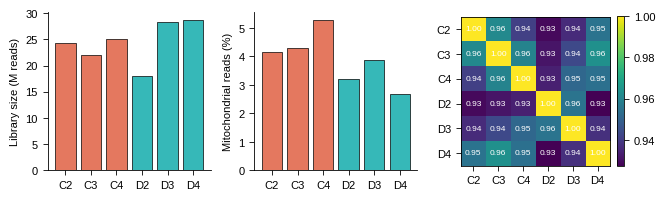

Saved: qc_panel.pdf


In [5]:
#@title 5 · QC figure — library size, mitochondrial fraction, correlation
with matplotlib.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(17*CM, 5.2*CM))
    colr = [COL_C if g == 'Control' else COL_D for g in qc.group]

    for ax, col, lab in [(axes[0], 'library_size_M', 'Library size (M reads)'),
                         (axes[1], 'mito_%_counts',  'Mitochondrial reads (%)')]:
        ax.bar(range(len(ALL)), qc[col], color=colr, edgecolor='black', linewidth=0.5)
        ax.set_xticks(range(len(ALL))); ax.set_xticklabels(ALL)
        ax.set_ylabel(lab, fontsize=8)
        ax.spines[['top','right']].set_visible(False)

    im = axes[2].imshow(cor.loc[ALL, ALL], cmap='viridis', vmin=float(np.min(cor.values)), vmax=1)
    axes[2].set_xticks(range(len(ALL))); axes[2].set_xticklabels(ALL)
    axes[2].set_yticks(range(len(ALL))); axes[2].set_yticklabels(ALL)
    if SHOW_TITLES: axes[2].set_title('Spearman correlation', fontsize=AHA_MIN_FONT)
    for i in range(len(ALL)):
        for j in range(len(ALL)):
            axes[2].text(j, i, f'{cor.loc[ALL[i], ALL[j]]:.2f}', ha='center', va='center',
                         fontsize=AHA_MIN_FONT - 2, color='white')
    fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig('qc_panel.pdf', bbox_inches='tight'); plt.show()
print('Saved: qc_panel.pdf')

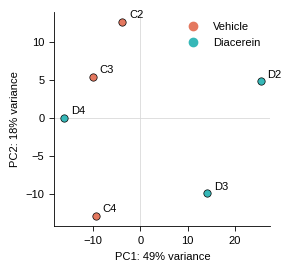

,PC1,PC2
C2,-3.9,12.6
C3,-10.1,5.4
C4,-9.5,-12.9
D2,25.4,4.8
D3,14.2,-9.9
D4,-16.1,0.0


Saved: pca.pdf, pca_coordinates.csv

PC1 separates two of three diacerein samples from the vehicles; the third (D4) sits at the far end of the vehicle side. With n=3 this cannot distinguish "D4 is aberrant" from "the response is heterogeneous" — the spread among vehicles on PC2 is of the same order.


In [6]:
#@title 6 · PCA on VST counts (all samples)
def vst_matrix(cnt, samples):
    sub  = cnt[samples]; sub = sub[sub.sum(axis=1) >= MIN_COUNT_SUM]
    meta = pd.DataFrame({'group': ['Control' if s in CTRL else 'Diacerein' for s in samples]},
                        index=samples)
    dds = DeseqDataSet(counts=sub.T, metadata=meta, design='~group', quiet=True)
    dds.vst()
    return pd.DataFrame(dds.layers['vst_counts'], index=samples, columns=sub.index).T

def pca(v, ntop=500):
    v = v.loc[v.var(axis=1).sort_values(ascending=False).index[:ntop]]
    x = (v.T - v.mean(axis=1)).values
    u, s, _ = np.linalg.svd(x, full_matrices=False)
    return pd.DataFrame((u*s)[:, :2], index=v.columns, columns=['PC1','PC2']), (s**2)/np.sum(s**2)*100

vst = vst_matrix(counts, ALL)
pcs, var = pca(vst)

with matplotlib.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(7.5*CM, 7*CM))
    for s in ALL:
        c = COL_C if s in CTRL else COL_D
        ax.scatter(pcs.loc[s,'PC1'], pcs.loc[s,'PC2'], s=28, color=c,
                   edgecolor='black', linewidth=0.5, zorder=3)
        ax.annotate(s, (pcs.loc[s,'PC1'], pcs.loc[s,'PC2']), textcoords='offset points',
                    xytext=(5,3), fontsize=AHA_MIN_FONT)
    ax.axhline(0, color='0.85', lw=0.6, zorder=1); ax.axvline(0, color='0.85', lw=0.6, zorder=1)
    ax.set_xlabel(f'PC1: {var[0]:.0f}% variance'); ax.set_ylabel(f'PC2: {var[1]:.0f}% variance')
    ax.spines[['top','right']].set_visible(False)
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([],[],marker='o',ls='',color=COL_C,label='Vehicle'),
                       Line2D([],[],marker='o',ls='',color=COL_D,label='Diacerein')],
              frameon=False, fontsize=AHA_MIN_FONT, loc='best')
    fig.tight_layout(); fig.savefig('pca.pdf', bbox_inches='tight'); plt.show()

display(pcs.round(1))
pcs.to_csv('pca_coordinates.csv')
print('Saved: pca.pdf, pca_coordinates.csv')
print('\nPC1 separates two of three diacerein samples from the vehicles; the third (D4) sits at the '
      'far end of the vehicle side. With n=3 this cannot distinguish "D4 is aberrant" from "the '
      'response is heterogeneous" — the spread among vehicles on PC2 is of the same order.')

In [7]:
#@title 7 · Differential expression — primary analysis (all six samples)
def run_deseq(cnt, samples, drop_genes=()):
    sub = cnt[samples].drop(index=list(drop_genes), errors='ignore')
    sub = sub[sub.sum(axis=1) >= MIN_COUNT_SUM]
    meta = pd.DataFrame({'group': ['Control' if s in CTRL else 'Diacerein' for s in samples]},
                        index=samples)
    dds = DeseqDataSet(counts=sub.T, metadata=meta, design='~group', quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=['group','Diacerein','Control'], quiet=True)
    st.summary()
    return st.results_df

def apply_filters(res, treat_samples):
    r  = res.dropna(subset=['padj']).copy()
    expr = (tpm[CTRL].mean(axis=1) >= TPM_MIN) | (tpm[treat_samples].mean(axis=1) >= TPM_MIN)
    keep = (r.padj < PADJ_CUT) & (r.log2FoldChange.abs() > LFC_CUT)
    sel  = r[keep]
    sel  = sel[expr.reindex(sel.index).fillna(False).values].copy()
    sel['gene_name'] = [sym.get(i, '') for i in sel.index]
    stages = {'padj < %.2g' % PADJ_CUT: int((r.padj < PADJ_CUT).sum()),
              '+ |log2FC| > %g' % LFC_CUT: int(keep.sum()),
              '+ mean TPM >= %g' % TPM_MIN: len(sel)}
    return stages, sel.sort_values('log2FoldChange')

PRIMARY   = [s for s in ALL if s not in PRIMARY_DROP]
PRIM_TREAT = [s for s in PRIMARY if s in TREAT]
res_primary = run_deseq(counts, PRIMARY)
stages, degs = apply_filters(res_primary, PRIM_TREAT)

print(f'Primary analysis — {len([x for x in PRIMARY if x in CTRL])} vehicle vs {len(PRIM_TREAT)} diacerein'
      + (f'   (excluded: {", ".join(PRIMARY_DROP)})' if PRIMARY_DROP else ''))
for k, v in stages.items():
    print(f'  {k:<22s} {v:>6d}')
print(f'  up {int((degs.log2FoldChange>0).sum())}, down {int((degs.log2FoldChange<0).sum())}')
display(degs[['gene_name','baseMean','log2FoldChange','lfcSE','pvalue','padj']])

Primary analysis — 3 vehicle vs 2 diacerein   (excluded: D4)
  padj < 0.05               597
  + |log2FC| > 1            380
  + mean TPM >= 1           343
  up 52, down 291


,gene_name,baseMean,log2FoldChange,lfcSE,pvalue,padj
gene_id,,,,,,
ENSRNOG00000002919,Gfap,208.491920,-7.263533,1.670604,1.374802e-05,1.100758e-03
ENSRNOG00000066556,Fgf23,558.494014,-7.209797,1.086704,3.254830e-11,1.421473e-08
ENSRNOG00000003171,Mpz,184.591771,-4.799670,1.522506,1.618895e-03,4.173794e-02
ENSRNOG00000086698,,69.800532,-4.492047,0.838189,8.357822e-08,1.508866e-05
ENSRNOG00000004341,C13h1orf116,185.209477,-4.034736,0.357844,1.741566e-29,2.509945e-25
...,...,...,...,...,...,...
ENSRNOG00000029886,Hba-a2,1723.773111,6.170303,1.312086,2.567843e-06,2.741315e-04
ENSRNOG00000081310,Hbb,1567.954814,6.264747,1.526165,4.044964e-05,2.650428e-03
ENSRNOG00000000167,Alas2,27.440141,7.496956,1.625677,3.995987e-06,3.944532e-04


In [8]:
#@title 8 · Sensitivity analyses
rows = []
runs = {
 f'Primary — {len(PRIMARY)} samples' + (f' (no {",".join(PRIMARY_DROP)})' if PRIMARY_DROP else ''):
                                        (PRIMARY, ()),
 'All 6 samples retained':              (ALL, ()),
 'Primary, mitochondrial genes removed':(PRIMARY, MITO),
}
if not MITO:
    runs.pop('Primary, mitochondrial genes removed')
    print('No mitochondrial genes identified (symbols missing) — that sensitivity run was skipped.')
stored = {}
for label, (samples, drop) in runs.items():
    treat = [s for s in samples if s in TREAT]
    r = run_deseq(counts, samples, drop)
    st, sel = apply_filters(r, treat)
    stored[label] = (r, sel)
    rows.append({'analysis': label,
                 'n_vehicle': len([s for s in samples if s in CTRL]),
                 'n_diacerein': len(treat),
                 **st,
                 'up': int((sel.log2FoldChange>0).sum()),
                 'down': int((sel.log2FoldChange<0).sum())})
sens = pd.DataFrame(rows).set_index('analysis')
display(sens)
sens.to_csv('sensitivity_summary.csv')

# side-by-side statistics for any genes of interest
WATCH = ['Selp','Csf2rb','Ripk1','Card9']
ids = {g: i for i, g in sym.items() if g in WATCH}
if ids:
    cmp = pd.DataFrame(index=[g for g in WATCH if g in ids.values()])
    for label, (r, _) in stored.items():
        for g, i in ids.items():
            if i in r.index:
                cmp.loc[g, f'log2FC [{label}]'] = round(r.loc[i,'log2FoldChange'], 2)
                cmp.loc[g, f'padj [{label}]']   = r.loc[i,'padj']
    display(cmp)
    cmp.to_csv('watchlist_across_analyses.csv')

,n_vehicle,n_diacerein,padj < 0.05,+ |log2FC| > 1,+ mean TPM >= 1,up,down
analysis,,,,,,,
Primary — 5 samples (no D4),3,2,597,380,343,52,291
All 6 samples retained,3,3,21,15,14,6,8
"Primary, mitochondrial genes removed",3,2,596,379,342,52,290


,log2FC [Primary — 5 samples (no D4)],padj [Primary — 5 samples (no D4)],log2FC [All 6 samples retained],padj [All 6 samples retained],"log2FC [Primary, mitochondrial genes removed]","padj [Primary, mitochondrial genes removed]"
Csf2rb,-3.01,1.346932e-20,-0.53,0.958569,-3.01,1.313187e-20
Selp,-3.82,2.752690e-15,-0.65,0.957776,-3.82,2.704522e-15
Ripk1,-1.26,2.410187e-03,-0.30,0.947774,-1.26,2.411381e-03
Card9,1.74,8.973696e-03,1.43,0.219512,1.74,9.023731e-03


In [9]:
#@title 8b · Fixed-size panel helper
def fixed_panel(w_cm=None, h_cm=None, margin=None):
    """Figure whose saved PDF is exactly w_cm x h_cm, with the axes inset by margin.
    Save with fig.savefig(path) and no bbox_inches, or the size changes."""
    w = w_cm or PANEL_W_CM; h = h_cm or PANEL_H_CM; m = margin or MARGIN
    fig = plt.figure(figsize=(w*CM, h*CM))
    ax  = fig.add_axes([m['l']/w, m['b']/h,
                        1-(m['l']+m['r'])/w, 1-(m['b']+m['t'])/h])
    return fig, ax

def report_size(path):
    import subprocess
    try:
        out = subprocess.run(['pdfinfo', path], capture_output=True, text=True).stdout
        line = [l for l in out.splitlines() if l.startswith('Page size')]
        if line:
            pts = [float(x) for x in line[0].split(':')[1].split('pts')[0].split('x')]
            print(f'  {path}: {pts[0]/28.35:.2f} x {pts[1]/28.35:.2f} cm')
    except FileNotFoundError:
        pass
print(f'Panels will be built at {PANEL_W_CM:.2f} x {PANEL_H_CM:.2f} cm.')


Panels will be built at 5.80 x 5.60 cm.


Not labelled (absent or not significant): Il1b


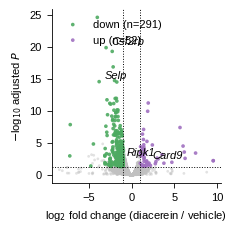

Saved: volcano_primary.pdf


In [10]:
#@title 9 · Volcano — primary analysis
r = res_primary.dropna(subset=['padj']).copy()
r['gene_name'] = [sym.get(i,'') for i in r.index]
expr = (tpm[CTRL].mean(axis=1) >= TPM_MIN) | (tpm[PRIM_TREAT].mean(axis=1) >= TPM_MIN)
r['sig'] = ((r.padj < PADJ_CUT) & (r.log2FoldChange.abs() > LFC_CUT)
            & expr.reindex(r.index).fillna(False).values)
r['cat'] = np.where(~r.sig, 'ns', np.where(r.log2FoldChange > 0, 'up', 'down'))
r['-log10padj'] = -np.log10(r.padj.clip(lower=1e-300))

with matplotlib.rc_context(STYLE):
    fig, ax = fixed_panel()
    for cat, col, z in [('ns',COL_NS,1), ('down',COL_DOWN,2), ('up',COL_UP,2)]:
        d = r[r.cat == cat]
        ax.scatter(d.log2FoldChange, d['-log10padj'], s=4 if cat=='ns' else 7,
                   color=col, alpha=0.45 if cat=='ns' else 0.9,
                   edgecolors='none', zorder=z,
                   label=None if cat=='ns' else f'{cat} (n={len(d)})')
    ax.axhline(-np.log10(PADJ_CUT), ls=':', lw=0.7, color='k')
    for x in (-LFC_CUT, LFC_CUT):
        ax.axvline(x, ls=':', lw=0.7, color='k')
    if LABEL_GENES:
        lab = r[r.sig & r.gene_name.isin(LABEL_GENES)]
        missing = [g for g in LABEL_GENES if g not in set(lab.gene_name)]
        if missing:
            print('Not labelled (absent or not significant):', ', '.join(missing))
    else:
        lab = r[r.sig & (r.gene_name != '')].nsmallest(N_LABEL, 'padj')
    for i, row in lab.iterrows():
        ax.annotate(row.gene_name, (row.log2FoldChange, row['-log10padj']),
                    textcoords='offset points', xytext=(4,2), fontsize=AHA_MIN_FONT, style='italic')
    ax.set_xlabel('log$_2$ fold change (diacerein / vehicle)')
    ax.set_ylabel('$-$log$_{10}$ adjusted $P$')
    ax.spines[['top','right']].set_visible(False)
    ax.legend(frameon=False, fontsize=AHA_MIN_FONT, loc='upper left')
    fig.savefig('volcano_primary.pdf'); plt.show()
print('Saved: volcano_primary.pdf'); report_size('volcano_primary.pdf')

In [11]:
#@title 11 · GO enrichment (g:Profiler) — up and down lists separately
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)

up_genes   = [g for g in degs[degs.log2FoldChange > 0].gene_name if g]
down_genes = [g for g in degs[degs.log2FoldChange < 0].gene_name if g]
print(f'Querying g:Profiler — {len(up_genes)} up, {len(down_genes)} down')

def go_query(genes, label):
    if not genes:
        print(f'  {label}: no genes'); return pd.DataFrame()
    r = gp.profile(organism='rnorvegicus', query=genes,
                   sources=['GO:BP','GO:MF','GO:CC'],
                   significance_threshold_method='fdr', user_threshold=0.05,
                   no_evidences=False)
    print(f'  {label}: {len(r)} significant terms')
    return r

go_up, go_down = go_query(up_genes, 'up'), go_query(down_genes, 'down')
GO = {}
for direction, tab in [('up', go_up), ('down', go_down)]:
    for s in ['GO:BP','GO:MF','GO:CC']:
        sub = tab[tab.source == s] if len(tab) else tab
        if len(sub):
            GO[f'{s.replace(":","_")}_{direction}'] = sub.sort_values('p_value')

with pd.ExcelWriter('GO_enrichment.xlsx') as xw:
    for name, tab in GO.items():
        tab.to_excel(xw, sheet_name=name[:31], index=False)
    degs.to_excel(xw, sheet_name='DEG_list')
print('Saved: GO_enrichment.xlsx', list(GO))

Querying g:Profiler — 46 up, 266 down
  up: 26 significant terms
  down: 988 significant terms
Saved: GO_enrichment.xlsx ['GO_MF_up', 'GO_CC_up', 'GO_BP_down', 'GO_MF_down', 'GO_CC_down']


In [12]:
#@title 12 · GSEA core functions
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter
from scipy.stats import false_discovery_control

def compute_es(ranked_genes, ranked_stats, gene_set):
    """Weighted running enrichment score (GSEA, p=1)."""
    S      = set(g.lower() for g in gene_set)
    in_set = np.array([g.lower() in S for g in ranked_genes])
    k      = in_set.sum()
    if k == 0: return np.zeros(len(ranked_genes)), 0, in_set
    w    = np.abs(ranked_stats) * in_set
    N_R  = w.sum()
    miss = 1.0 / (len(ranked_genes) - k)
    curve = np.cumsum(np.where(in_set, w / N_R, -miss))
    peak  = curve[np.argmax(np.abs(curve))]
    return curve, peak, in_set

def perm_pval(in_set, w, N_R, miss, obs_peak, n_perm=10000, seed=42, batch=500):
    """Batched vectorised permutation p-value."""
    rng = np.random.default_rng(seed)
    n, count, done = len(in_set), 0, 0
    while done < n_perm:
        bs     = min(batch, n_perm - done)
        idx    = np.argsort(rng.random((bs, n)), axis=1)
        steps  = np.where(in_set[idx], w[idx] / N_R, -miss)
        curves = np.cumsum(steps, axis=1)
        peaks  = curves[np.arange(bs), np.argmax(np.abs(curves), axis=1)]
        count += int((np.abs(peaks) >= abs(obs_peak)).sum())
        done  += bs
    return (count + 1) / (n_perm + 1)

def run_gsea_sets(rk_genes, rk_stats, gene_sets_dict, n_perm=10000):
    results, raw_p = {}, []
    for sname, sinfo in gene_sets_dict.items():
        curve, peak, in_set = compute_es(rk_genes, rk_stats, sinfo['genes'])
        w    = np.abs(rk_stats) * in_set
        N_R  = w.sum()
        k    = in_set.sum()
        miss = 1.0 / max(len(rk_genes) - k, 1)
        pval = perm_pval(in_set, w, N_R, miss, peak, n_perm=n_perm)
        results[sname] = {'curve': curve, 'peak_es': peak, 'pval': pval,
                          'in_set': in_set, 'n_hits': int(k)}
        raw_p.append(pval)
    for sname, ap in zip(gene_sets_dict, false_discovery_control(raw_p, method='bh')):
        results[sname]['adj_pval'] = ap
    return results
print('GSEA functions defined.')

GSEA functions defined.


In [13]:
#@title 14 · GSEA figure (fixed width, fits the panel slot)
def plot_gsea(rk_genes, rk_stats, gene_sets_dict, gs_results,
              title, out_path, treat_label='Diacerein',
              w_cm=None, h_cm=None):
    """Three stacked axes inside a figure of exactly w_cm x h_cm:
    direction strip, running-ES curves, hit barcode."""
    w = w_cm or PANEL_W_CM; h = h_cm or PANEL_H_CM
    N, ns = len(rk_genes), len(gene_sets_dict)
    L, R, B, T = MARGIN['l'], MARGIN['r'], MARGIN['b'], MARGIN['t']
    strip_h, bar_h = 0.40, 0.18 * ns                 # cm
    es_h = h - B - T - strip_h - bar_h
    x0, wd = L/w, 1 - (L+R)/w

    fig = plt.figure(figsize=(w*CM, h*CM))
    ax_arr = fig.add_axes([x0, (B + bar_h + es_h)/h, wd, strip_h/h])
    ax_es  = fig.add_axes([x0, (B + bar_h)/h,        wd, es_h/h])
    ax_bar = fig.add_axes([x0,  B/h,                 wd, bar_h/h])

    # direction strip
    ax_arr.set_xlim(0, 1); ax_arr.set_ylim(0, 1); ax_arr.axis('off')
    ax_arr.annotate('', xy=(0.0, 0.55), xytext=(0.30, 0.55),
                    xycoords='axes fraction', textcoords='axes fraction',
                    arrowprops=dict(arrowstyle='->', color='#b2182b', lw=1.2))
    ax_arr.text(0.32, 0.55, 'Up', fontsize=AHA_MIN_FONT, color='#b2182b', va='center')
    ax_arr.annotate('', xy=(1.0, 0.55), xytext=(0.70, 0.55),
                    xycoords='axes fraction', textcoords='axes fraction',
                    arrowprops=dict(arrowstyle='->', color='#2166ac', lw=1.2))
    ax_arr.text(0.68, 0.55, 'Down', fontsize=AHA_MIN_FONT, color='#2166ac',
                va='center', ha='right')

    # running enrichment score
    for sname, sinfo in gene_sets_dict.items():
        ax_es.plot(np.arange(N), gs_results[sname]['curve'],
                   color=sinfo['color'], lw=1.2, alpha=0.9)
    ax_es.axhline(0, color='black', lw=0.6, ls='--', alpha=0.7)
    ax_es.set_xlim(0, N)
    curves = [gs_results[s]['curve'] for s in gene_sets_dict]
    lo = min(c.min() for c in curves); hi = max(c.max() for c in curves)
    ax_es.set_ylim(lo * 1.15, max(hi * 3.2, 0.05))
    ax_es.set_ylabel('Running ES', fontsize=AHA_MIN_FONT)
    ax_es.tick_params(axis='y', labelsize=AHA_MIN_FONT)
    ax_es.set_xticks([])
    for sp in ['top', 'right', 'bottom']:
        ax_es.spines[sp].set_visible(False)
    if SHOW_TITLES:
        ax_es.set_title(title, fontsize=AHA_MIN_FONT + 2, fontweight='bold', pad=3)

    lines = []
    for sname, sinfo in gene_sets_dict.items():
        lab = short_name(sname)
        if LEGEND_WITH_STATS:
            r = gs_results[sname]
            lab += f"  ES={r['peak_es']:.2f}"
        lines.append(Line2D([0], [0], color=sinfo['color'], lw=1.6, label=lab))
    ax_es.legend(handles=lines, fontsize=AHA_MIN_FONT, frameon=False,
                 loc='lower left', bbox_to_anchor=(0.0, 0.02),
                 handlelength=1.1, handletextpad=0.5, labelspacing=0.25,
                 borderpad=0.0, borderaxespad=0.0)

    # hit barcode, one row per set, colour-matched to the legend
    ax_bar.set_xlim(0, N); ax_bar.set_ylim(0, ns)
    ax_bar.set_yticks([])
    for sp in ax_bar.spines.values():
        sp.set_visible(False)
    for row_i, (sname, sinfo) in enumerate(gene_sets_dict.items()):
        for hit in np.where(gs_results[sname]['in_set'])[0]:
            ax_bar.axvline(hit, ymin=row_i/ns, ymax=(row_i + 0.82)/ns,
                           color=sinfo['color'], lw=0.5, alpha=0.85)
    ticks = np.linspace(0, N - 1, 4, dtype=int)
    ax_bar.xaxis.set_major_locator(FixedLocator(ticks))
    ax_bar.xaxis.set_major_formatter(FixedFormatter([f'{rk_stats[r]:.0f}' for r in ticks]))
    ax_bar.tick_params(axis='x', labelsize=AHA_MIN_FONT, length=2.5)
    ax_bar.set_xlabel('Wald statistic', fontsize=AHA_MIN_FONT, labelpad=2)

    fig.savefig(out_path, format='pdf')      # no bbox_inches: size stays exact
    plt.show(); plt.close()
    print(f'Saved → {out_path}'); report_size(out_path)
print('Plot function defined.')


Plot function defined.


In [14]:
#@title 14 · KEGG gene sets
KEGG_SETS = {
    'Cytokine–cytokine receptor interaction': {
        'color': '#c0406a',
        'genes': [
            'Il1a','Il1b','Il2','Il3','Il4','Il5','Il6','Il7','Il9','Il10','Il11',
            'Il12a','Il12b','Il13','Il15','Il17a','Il18','Il19','Il20','Il21','Il22',
            'Il23a','Il24','Il25','Il27','Il31','Il33','Tnf','Tnfsf10','Tnfsf11',
            'Tnfsf13','Tnfsf13b','Tnfsf14','Tnfsf15','Ifng','Tgfb1','Tgfb2','Tgfb3',
            'Csf1','Csf2','Csf3','Vegfa','Vegfb','Vegfc','Pdgfa','Pdgfb','Egf','Kitlg',
            'Ccl2','Ccl3','Ccl4','Ccl5','Ccl7','Ccl11','Ccl17','Ccl19','Ccl20','Ccl21',
            'Ccl22','Ccl25','Cxcl1','Cxcl2','Cxcl5','Cxcl9','Cxcl10','Cxcl11','Cxcl12',
            'Cxcl13','Cx3cl1','Il1r1','Il1r2','Il2ra','Il2rb','Il2rg','Il4r','Il5ra',
            'Il6r','Il6st','Il7r','Il10ra','Il10rb','Il12rb1','Il12rb2','Il13ra1','Il15ra',
            'Il17ra','Il18r1','Il21r','Tnfrsf1a','Tnfrsf1b','Tnfrsf10a','Tnfrsf10b',
            'Tnfrsf11a','Tnfrsf11b','Tnfrsf13b','Tnfrsf14','Ifnar1','Ifnar2','Ifngr1',
            'Ifngr2','Tgfbr1','Tgfbr2','Csf1r','Csf2ra','Csf2rb','Csf3r','Flt1','Kdr',
            'Flt4','Pdgfra','Pdgfrb','Egfr','Met','Kit','Ccr1','Ccr2','Ccr3','Ccr4',
            'Ccr5','Ccr6','Ccr7','Ccr8','Ccr9','Cx3cr1','Cxcr1','Cxcr2','Cxcr3','Cxcr4','Cxcr5'],
    },
    'NF-κB signaling pathway': {
        'color': '#3a9e9e',
        'genes': [
            'Tnf','Il1a','Il1b','Lta','Ltb','Cd40lg','Tnfsf11','Tnfsf13b','Tnfsf12',
            'Tnfsf10','Fasl','Ngf','Tlr1','Tlr2','Tlr3','Tlr4','Tlr5','Tlr6','Tlr7',
            'Tlr8','Tlr9','Nod1','Nod2','Ripk2','Traf1','Traf2','Traf3','Traf5','Traf6',
            'Irak1','Irak4','Tab1','Tab2','Map3k7','Chuk','Ikbkb','Ikbkg','Nfkbia',
            'Nfkbib','Nfkbie','Nfkb1','Nfkb2','Rela','Relb','Bcl3','Card11','Malt1',
            'Bcl10','Pidd1','Casp8','Tradd','Fadd','Ripk1','Cyld','Akt1','Gsk3b',
            'Pim1','Bcl2','Bcl2l1','Xiap','Birc3','Ccnd1','Il6','Cxcl1','Cxcl2',
            'Vcam1','Icam1','Csf2'],
    },
    'TNF signaling pathway': {
        'color': '#5a4a8a',
        'genes': [
            'Tnf','Tnfrsf1a','Tnfrsf1b','Tradd','Traf2','Traf3','Traf5','Ripk1',
            'Fadd','Casp8','Casp3','Casp6','Casp7','Bid','Cyld','Map3k7','Tab1','Tab2',
            'Chuk','Ikbkb','Ikbkg','Nfkb1','Rela','Nfkbia','Mapk8','Mapk9','Mapk14',
            'Map2k3','Map2k4','Map2k6','Map2k7','Mapk3','Mapk1','Map2k1','Map2k2',
            'Akt1','Mlkl','Ripk3','Fas','Casp1','Il1b','Il6','Icam1','Vcam1','Ccl2',
            'Cxcl1','Cxcl2','Cxcl10','Mmp3','Mmp9','Ptgs2','Nos2','Birc2','Birc3',
            'Nfkbia','Tnfaip3','Bcl2l1','Bcl2','Sod2','Ccnd1','Vegfa','Cxcl5',
            'Ccl20','Il18','Tlr3','Tlr4'],
    },
}
print('KEGG sets:', list(KEGG_SETS))

KEGG sets: ['Cytokine–cytokine receptor interaction', 'NF-κB signaling pathway', 'TNF signaling pathway']


Genes ranked: 14,707  (stat -11.28 to 7.83)
  Cytokine–cytokine receptor interaction: ES=-0.444  adj.p=0.0001  hits=94
  NF-κB signaling pathway: ES=-0.440  adj.p=0.0001  hits=63
  TNF signaling pathway: ES=-0.418  adj.p=0.0001  hits=61


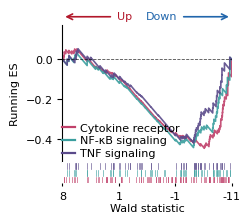

Saved → GSEA_KEGG_DvsC.pdf
Saved: GSEA_KEGG_results.csv


In [15]:
#@title 15 · Run KEGG GSEA on the primary analysis
rk = res_primary.dropna(subset=['stat']).copy()
rk['gene_name'] = [sym.get(i, '') for i in rk.index]
rk = rk[rk.gene_name != ''].sort_values('stat', ascending=False)
rk_genes, rk_stats = rk.gene_name.str.lower().values, rk.stat.values
print(f'Genes ranked: {len(rk_genes):,}  (stat {rk_stats.min():.2f} to {rk_stats.max():.2f})')

kegg_results = run_gsea_sets(rk_genes, rk_stats, KEGG_SETS)
for sname, r in kegg_results.items():
    print(f'  {sname}: ES={r["peak_es"]:.3f}  adj.p={r["adj_pval"]:.4f}  hits={r["n_hits"]}')

plot_gsea(rk_genes, rk_stats, KEGG_SETS, kegg_results,
          title='KEGG Pathway Enrichment — Diacerein vs Control',
          out_path='GSEA_KEGG_DvsC.pdf')

pd.DataFrame([{'gene_set': s, 'ES': r['peak_es'], 'n_hits': r['n_hits'],
               'pval': r['pval'], 'adj_pval': r['adj_pval']}
              for s, r in kegg_results.items()]).to_csv('GSEA_KEGG_results.csv', index=False)
print('Saved: GSEA_KEGG_results.csv')

In [18]:
#@title 10 · Export
res_out = res_primary.copy()
res_out['gene_name'] = [sym.get(i,'') for i in res_out.index]
res_out.to_csv('DESeq2_primary_full.csv')
degs.to_csv('DEGs_primary.csv')

with pd.ExcelWriter('rnaseq_v12_results.xlsx') as xw:
    qc.to_excel(xw, sheet_name='QC')
    pcs.round(3).to_excel(xw, sheet_name='PCA')
    sens.to_excel(xw, sheet_name='Sensitivity')
    degs.to_excel(xw, sheet_name='DEGs_primary')
    res_out.to_excel(xw, sheet_name='DESeq2_full')
    for name, tab in (GO.items() if 'GO' in dir() else []):
        tab.to_excel(xw, sheet_name=name[:31], index=False)

print('Wrote: rnaseq_v12_results.xlsx, DESeq2_primary_full.csv, DEGs_primary.csv,')
print('       qc_samples.csv, pca_coordinates.csv, sensitivity_summary.csv,')
print('       qc_panel.pdf, pca.pdf, volcano_primary.pdf, GSEA_KEGG_DvsC.pdf,')
print('       GO_enrichment.xlsx, GSEA_KEGG_results.csv')
try:
    from google.colab import files
    for f in ['rnaseq_v12_results.xlsx', 'qc_panel.pdf', 'pca.pdf', 'volcano_primary.pdf', 'GSEA_KEGG_DvsC.pdf', 'GSEA_KEGG_results.csv']:
        files.download(f)
except ImportError:
    pass

Wrote: rnaseq_v12_results.xlsx, DESeq2_primary_full.csv, DEGs_primary.csv,
       qc_samples.csv, pca_coordinates.csv, sensitivity_summary.csv,
       qc_panel.pdf, pca.pdf, volcano_primary.pdf, GSEA_KEGG_DvsC.pdf,
       GO_enrichment.xlsx, GSEA_KEGG_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>